In [1]:
from qiskit import __version__
print(__version__)

2.4.1


# Importing Packages

In [2]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector, state_fidelity, Pauli, DensityMatrix, partial_trace
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from qiskit_aer.library import SaveDensityMatrix, SaveStatevector, SetDensityMatrix
from qiskit import transpile 
import numpy as np
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
from qiskit.circuit.library import HGate, UnitaryGate, IGate
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, NullFormatter
from matplotlib.gridspec import GridSpec
from scipy.optimize import curve_fit

# Defining Global Variable

In [3]:
x_star = 1/3 * (-2 + np.cbrt(19-3*np.sqrt(33)) + np.cbrt(19+3*np.sqrt(33)))
z_star = np.sqrt(1 - x_star**2)
theta = np.arcsin(x_star)

# Graphing Settings

In [4]:
mpl.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
    'font.size': 8,
    'axes.labelsize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'lines.linewidth': 1.2,
    'figure.dpi': 150,
})

# Defining Numpy Matrices

In [5]:
identity = np.array([[1,0], [0,1]])
ry_theta = np.array([[np.cos(theta/2), -np.sin(theta/2)], [np.sin(theta/2), np.cos(theta/2)]])

# Infidelity to Error Rates

In [6]:
def inf_to_error(infidelity_list, num_qubits):
    error_rates_list = []
    dimension = 2**num_qubits
    for infidelity in infidelity_list:
        error_rates_list.append( infidelity * (dimension / (dimension - 1)) )
    
    return error_rates_list

In [7]:
one_qubit_gate_infidelity = [2.8e-5 * i for i in range(1,6)]
two_qubit_gate_infidelity = [8.3e-4 * i for i in range(1,6)]
idle_gate_infidelity = [1.2e-4 * i for i in range(1,6)]
spam0 = [6.7e-4 * i for i in range(1,6)] # P(1|0), measured 1 given that 0 was prepared
spam1 = [1.2e-3 * i for i in range(1,6)] # P(0|1)

In [8]:
one_qubit_gate_error_prob = inf_to_error(one_qubit_gate_infidelity, num_qubits=1)
two_qubit_gate_error_prob = inf_to_error(two_qubit_gate_infidelity, num_qubits=2)
idle_gate_error_prob = inf_to_error(idle_gate_infidelity, num_qubits=1)

# Simulations

Consider the case when only state preparation is noisy

In [35]:
ideal = QuantumCircuit(2)
ideal.ry(theta,0)
ideal_dm = DensityMatrix(ideal)

ideal_1q = QuantumCircuit(1)
ideal_1q.ry(theta,0)
ideal_1q_dm = DensityMatrix(ideal_1q)

In [36]:
alpha_star = np.sqrt((1-x_star)/2)
beta_star = -np.sqrt((1+x_star)/2)
ket_bar = alpha_star * np.array([[1],[0]]) + beta_star * np.array([[0],[1]])

def kraus0(error_prob):
    return np.sqrt(1-error_prob) * np.eye(2)
def kraus1(error_prob):
    return np.sqrt(error_prob) * np.matmul(ket_bar, np.array([[1,0]]))
def kraus2(error_prob):
    return np.sqrt(error_prob) * np.matmul(ket_bar, np.array([[0,1]]))

In [37]:
# Number of distillation rounds and simulation shots per round.
rounds = 50
shots = 50

# Initialize the first-round input error rate.
error_prob = one_qubit_gate_error_prob[4] 

# Store the output infidelity after each round.
infidelity_list = []

# Initial single-qubit input density matrix, and adding its infidelity to the infidelity list
prep = ry_theta @ np.matmul([[1],[0]], [[1,0]]) @ ry_theta.conj().T
rho_in = kraus0(error_prob) @ prep @ kraus0(error_prob).conj().T + kraus1(error_prob) @ prep @ kraus1(error_prob).conj().T + kraus2(error_prob) @ prep @ kraus2(error_prob).conj().T
rho_in = rho_in / np.trace(rho_in)
temp = DensityMatrix(rho_in)
infidelity_list.append(1 - state_fidelity(ideal_1q_dm, temp))

for r in range(rounds):
    # Building the input density matrix
    rho_two = DensityMatrix(np.kron(rho_in.data, rho_in.data))
    meas_circuit = QuantumCircuit(2, 1)
    meas_circuit.append(SetDensityMatrix(rho_two), meas_circuit.qubits)

    # Two-qubit distillation decoder
    meas_circuit.cx(0, 1)
    meas_circuit.h(0)

    # Measure out qubit 1 and postselect on 0
    meas_circuit.measure([1], [0])

    # Measure for post-selection and save the conditional density matrix.
    meas_circuit.append(
        SaveDensityMatrix(
            num_qubits=2,
            label="dm_post",
            conditional=True,
            pershot=True
        ),
        meas_circuit.qubits
    )

    # Run the density-matrix simulation.
    noise_model = NoiseModel()
    backend = AerSimulator(noise_model=noise_model, method='density_matrix')
    job = backend.run(meas_circuit, shots=shots)
    result = job.result()
    
    # Compute the accepted output infidelity.
    res_dm = result.data()['dm_post']
    rho_post_2q = res_dm["0x0"][0]
    infidelity_list.append(1 - state_fidelity(rho_post_2q, ideal_dm))
    
    # Turn output into next round's input density matrix
    rho_out = partial_trace(rho_post_2q, [1])
    rho_in = rho_out

A = 5.204753e-04
lambda = 1.725752e-01
per-round decay factor = 8.414950e-01


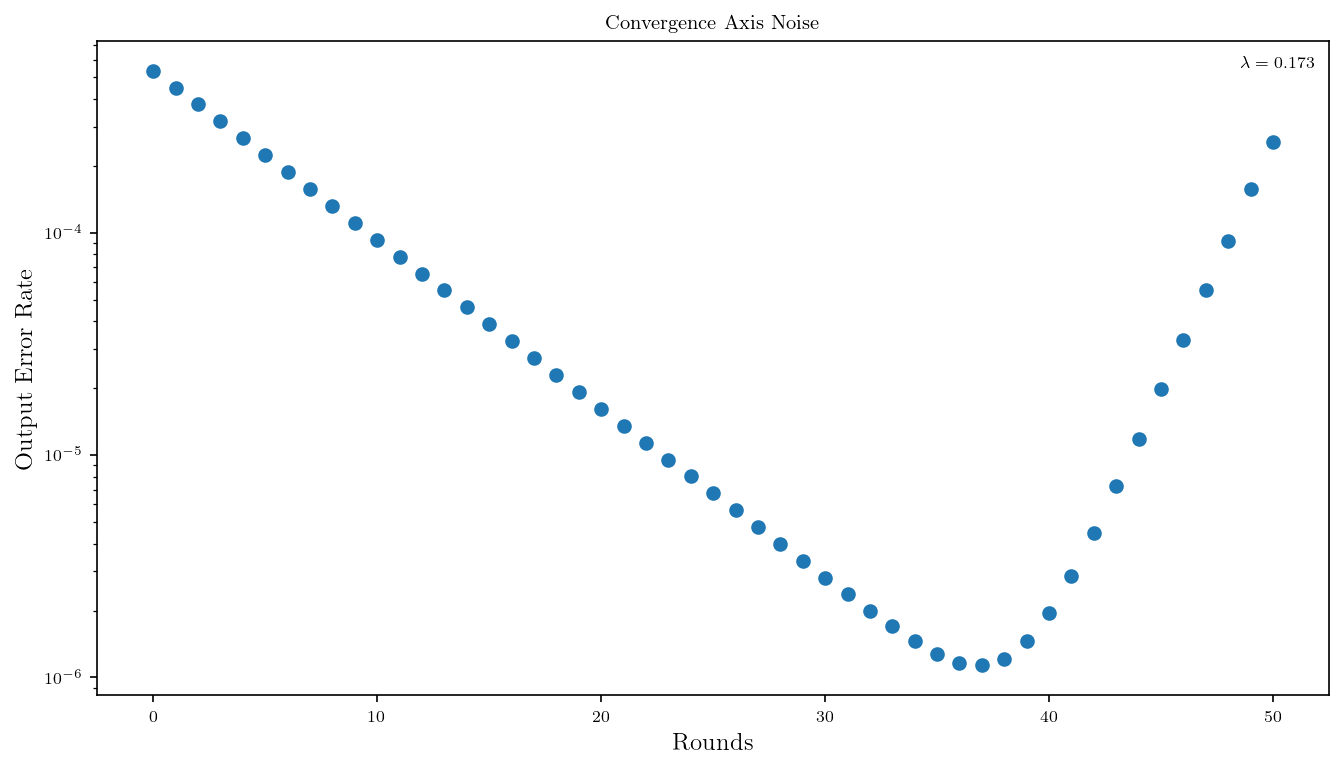

In [38]:
rounds_arr = np.array([r for r in range(rounds+1)])
output_error_rate = np.asarray(inf_to_error(infidelity_list, 1))

# Fit only the left, decreasing branch
# From your plot this looks roughly like rounds 0 to 16
fit_start = 0
fit_end = 37 # inclusive

mask = (rounds_arr >= fit_start) & (rounds_arr <= fit_end)

x_fit = rounds_arr[mask]
y_fit = output_error_rate[mask]

# Fit log(y) = a r + b
a, b = np.polyfit(x_fit, np.log(y_fit), 1)

lambda_ = -a          # exponential decay parameter
A = np.exp(b)       # prefactor
decay_factor = np.exp(a)  # multiplicative factor per round

print(f"A = {A:.6e}")
print(f"lambda = {lambda_:.6e}")
print(f"per-round decay factor = {decay_factor:.6e}")

# Fitted curve over the fitting region
y_fit_curve = A * np.exp(-lambda_ * x_fit)

plt.figure(figsize=(9, 5))

plt.plot(rounds_arr, output_error_rate, 'o', label='Output')
plt.xlabel("Rounds", fontsize=12)
plt.ylabel("Output Error Rate", fontsize=12)
plt.yscale('log')
plt.tight_layout()
# Legend with text only
dummy = plt.Line2D([], [], linestyle='none', label=rf'$\lambda={lambda_:.3g}$')
plt.legend(
    handles=[dummy],
    frameon=False,
    loc='upper right',
    handlelength=0,
    handletextpad=0
)
plt.title("Convergence Axis Noise")
plt.show()

Multiple input error rates on the same plot

In [39]:
rounds = 65
shots = 50

# Current error probability is the upper bound.
max_input_error = one_qubit_gate_error_prob[4]

# Six logarithmically spaced values from p_max down to p_max / 1000.
num_input_errors = 6
min_input_error = max_input_error * 1e-3

input_error_prob_list = np.geomspace(
    max_input_error,
    min_input_error,
    num=num_input_errors,
)

rounds_arr = np.arange(rounds + 1)

# The backend can be constructed once.
backend = AerSimulator(method="density_matrix")


def run_distillation(input_error_prob):
    """Return the output-error-rate curve for one initial error probability."""

    infidelity_list = []

    # Initial noisy single-qubit density matrix.
    prep = (
        ry_theta
        @ np.array([[1], [0]])
        @ np.array([[1, 0]])
        @ ry_theta.conj().T
    )

    rho_in = (
        kraus0(input_error_prob)
        @ prep
        @ kraus0(input_error_prob).conj().T
        +
        kraus1(input_error_prob)
        @ prep
        @ kraus1(input_error_prob).conj().T
        +
        kraus2(input_error_prob)
        @ prep
        @ kraus2(input_error_prob).conj().T
    )

    rho_in = DensityMatrix(rho_in / np.trace(rho_in))

    initial_infidelity = 1 - state_fidelity(
        ideal_1q_dm,
        rho_in,
    )
    infidelity_list.append(initial_infidelity)

    for _ in range(rounds):
        rho_two = DensityMatrix(
            np.kron(rho_in.data, rho_in.data)
        )

        meas_circuit = QuantumCircuit(2, 1)
        meas_circuit.append(
            SetDensityMatrix(rho_two),
            meas_circuit.qubits,
        )

        # Two-qubit distillation decoder.
        meas_circuit.cx(0, 1)
        meas_circuit.h(0)

        # Measure qubit 1 and postselect on outcome 0.
        meas_circuit.measure(1, 0)

        meas_circuit.append(
            SaveDensityMatrix(
                num_qubits=2,
                label="dm_post",
                conditional=True,
                pershot=True,
            ),
            meas_circuit.qubits,
        )

        result = backend.run(
            meas_circuit,
            shots=shots,
        ).result()

        conditional_states = result.data()["dm_post"]

        if "0x0" not in conditional_states:
            raise RuntimeError(
                "No postselected 0 outcome was sampled. "
                "Increase the number of shots."
            )

        # All accepted shots have the same conditional density matrix
        # for this ideal decoder, so taking the first one is sufficient.
        rho_post_2q = conditional_states["0x0"][0]

        output_infidelity = 1 - state_fidelity(
            rho_post_2q,
            ideal_dm,
        )
        infidelity_list.append(output_infidelity)

        # Retain qubit 0 as the input to the next round.
        rho_in = partial_trace(rho_post_2q, [1])

    return np.asarray(inf_to_error(infidelity_list, 1))


# Simulate all initial error probabilities.
output_curves = {}

for input_error_prob in input_error_prob_list:
    output_curves[input_error_prob] = run_distillation(
        input_error_prob
    )

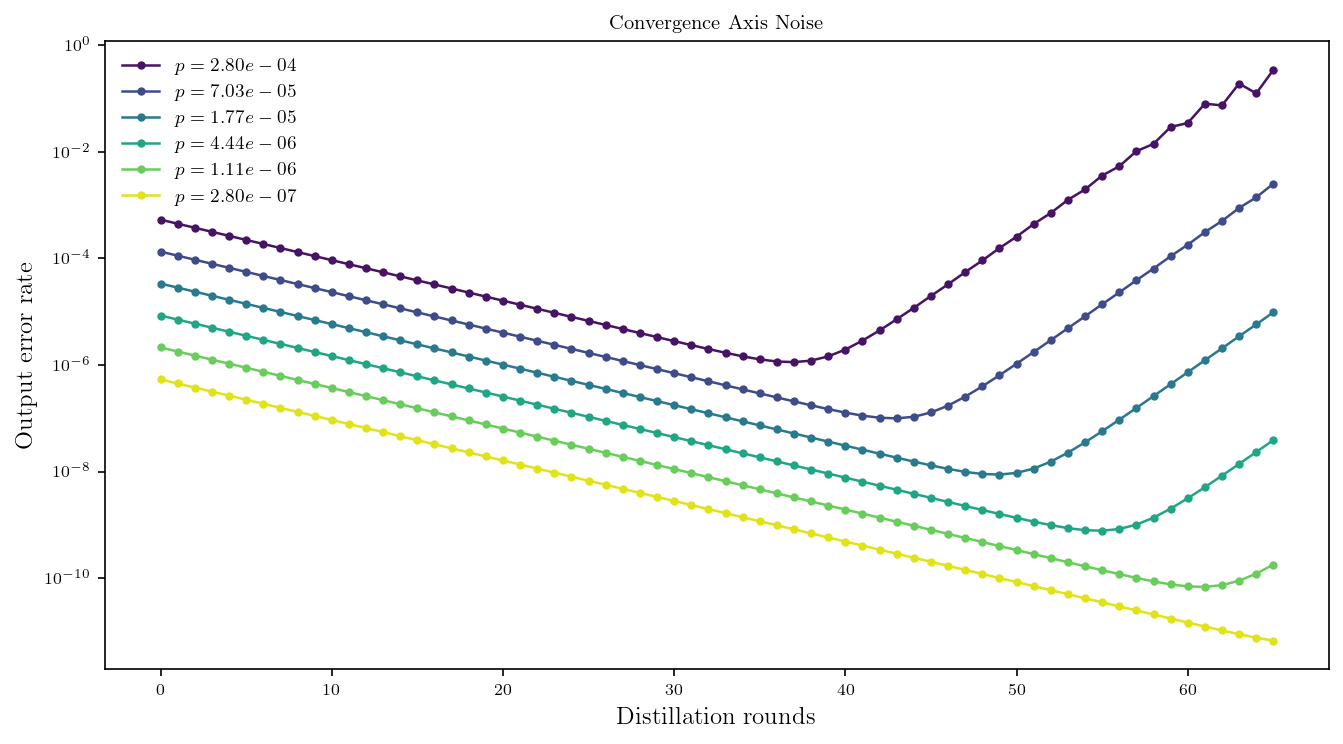

In [40]:
fit_start = 0
fit_end = 37

colors = plt.cm.viridis(
    np.linspace(0.05, 0.95, len(input_error_prob_list))
)

plt.figure(figsize=(9, 5))

for color, input_error_prob in zip(
    colors,
    input_error_prob_list,
):
    output_error_rate = output_curves[input_error_prob]

    # Fit only finite, strictly positive values.
    fit_mask = (
        (rounds_arr >= fit_start)
        & (rounds_arr <= fit_end)
        & np.isfinite(output_error_rate)
        & (output_error_rate > 0)
    )

    x_fit = rounds_arr[fit_mask]
    y_fit = output_error_rate[fit_mask]

    if len(x_fit) >= 2:
        slope, intercept = np.polyfit(
            x_fit,
            np.log(y_fit),
            1,
        )
        lambda_ = -slope
        label = (
            rf"$p={input_error_prob:.2e}$"
        )
    else:
        label = rf"$p={input_error_prob:.2e}$"

    plt.plot(
        rounds_arr,
        output_error_rate,
        marker="o",
        markersize=3,
        linewidth=1.2,
        color=color,
        label=label,
    )

plt.xlabel("Distillation rounds", fontsize=12)
plt.ylabel("Output error rate", fontsize=12)
plt.yscale("log")
plt.title("Convergence Axis Noise")
plt.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

# Analysis

Finding the round and infidelity where the MSD protocols begins to fail

In [24]:
error_rate_threshold = 1
round_threshold = 0
for i in range(len(output_error_rate)):
    if output_error_rate[i] < error_rate_threshold:
        error_rate_threshold = output_error_rate[i]
        round_threshold = i
    else:
        break

In [25]:
print(error_rate_threshold)
print(round_threshold)

2.48245868306185e-13
70


# Theoretical Estimate of Distillation Round Threshold

In [17]:
c10 = x_star
c20 = -0.95907
p = one_qubit_gate_error_prob[4]

m = np.log( (1-c10)/(np.abs(c20)*p*(x_star+z_star)) ) / np.abs(np.log(c10))
print(m)

infidelity_threshold = (c10**m * p*(x_star+z_star))*(x_star+z_star) / 2
print(f"Infidelity Threshold: {infidelity_threshold}")

output_error_rate_threshold = inf_to_error([infidelity_threshold], 1)[0]
print(f"Output Error Rate Threshold: {output_error_rate_threshold}")

34.64636043311555
Infidelity Threshold: 6.187688118652448e-07
Output Error Rate Threshold: 1.2375376237304897e-06


# Saving Data

In [33]:
# Arrange all curves into one 2D array.
# Row j corresponds to input_error_prob_list[j].
output_error_rate_matrix = np.stack([
    output_curves[input_error_prob]
    for input_error_prob in input_error_prob_list
])


# Find the minimum before each curve first stops decreasing.
simulation_round_thresholds = np.zeros(
    len(input_error_prob_list),
    dtype=int,
)

simulation_output_error_rate_thresholds = np.zeros(
    len(input_error_prob_list),
    dtype=float,
)

for j, output_error_rate in enumerate(output_error_rate_matrix):
    error_rate_threshold = output_error_rate[0]
    round_threshold = 0

    for i in range(1, len(output_error_rate)):
        if (
            np.isfinite(output_error_rate[i])
            and output_error_rate[i] < error_rate_threshold
        ):
            error_rate_threshold = output_error_rate[i]
            round_threshold = i
        else:
            break

    simulation_round_thresholds[j] = round_threshold
    simulation_output_error_rate_thresholds[j] = (
        error_rate_threshold
    )


# Calculate the exponential fit parameters separately for each curve.
fit_start = 0
fit_end = 37

lambda_values = np.full(
    len(input_error_prob_list),
    np.nan,
)
fit_prefactors = np.full(
    len(input_error_prob_list),
    np.nan,
)
per_round_decay_factors = np.full(
    len(input_error_prob_list),
    np.nan,
)

for j, output_error_rate in enumerate(output_error_rate_matrix):
    fit_mask = (
        (rounds_arr >= fit_start)
        & (rounds_arr <= fit_end)
        & np.isfinite(output_error_rate)
        & (output_error_rate > 0)
    )

    x_fit = rounds_arr[fit_mask]
    y_fit = output_error_rate[fit_mask]

    if len(x_fit) >= 2:
        slope, intercept = np.polyfit(
            x_fit,
            np.log(y_fit),
            1,
        )

        lambda_values[j] = -slope
        fit_prefactors[j] = np.exp(intercept)
        per_round_decay_factors[j] = np.exp(slope)


# Calculate the theoretical thresholds for every input error probability.
c10 = x_star
c20 = -0.95907

theoretical_round_thresholds = (
    np.log(
        (1 - c10)
        / (
            np.abs(c20)
            * input_error_prob_list
            * (x_star + z_star)
        )
    )
    / np.abs(np.log(c10))
)

# If a discrete round number is needed, round upward.
theoretical_round_thresholds_integer = np.ceil(
    theoretical_round_thresholds
).astype(int)

theoretical_infidelity_thresholds = (
    c10**theoretical_round_thresholds
    * input_error_prob_list
    * (x_star + z_star)**2
    / 2
)

theoretical_output_error_rate_thresholds = np.asarray([
    inf_to_error([infidelity_threshold], 1)[0]
    for infidelity_threshold in theoretical_infidelity_thresholds
])


# Print a summary.
for j, input_error_prob in enumerate(input_error_prob_list):
    print(f"\nInput error probability: {input_error_prob:.6e}")
    print(
        "Simulation round threshold: "
        f"{simulation_round_thresholds[j]}"
    )
    print(
        "Theoretical round threshold: "
        f"{theoretical_round_thresholds[j]:.6f}"
    )
    print(
        "Simulation output-error threshold: "
        f"{simulation_output_error_rate_thresholds[j]:.6e}"
    )
    print(
        "Theoretical infidelity threshold: "
        f"{theoretical_infidelity_thresholds[j]:.6e}"
    )
    print(
        "Theoretical output-error threshold: "
        f"{theoretical_output_error_rate_thresholds[j]:.6e}"
    )
    print(f"Fitted lambda: {lambda_values[j]:.6e}")


Input error probability: 2.800000e-04
Simulation round threshold: 37
Theoretical round threshold: 34.646360
Simulation output-error threshold: 1.132157e-06
Theoretical infidelity threshold: 6.187688e-07
Theoretical output-error threshold: 1.237538e-06
Fitted lambda: 1.725752e-01

Input error probability: 7.033282e-05
Simulation round threshold: 43
Theoretical round threshold: 42.531798
Simulation output-error threshold: 9.953627e-08
Theoretical infidelity threshold: 3.904167e-08
Theoretical output-error threshold: 7.808335e-08
Fitted lambda: 1.751449e-01

Input error probability: 1.766681e-05
Simulation round threshold: 49
Theoretical round threshold: 50.417235
Simulation output-error threshold: 8.767132e-09
Theoretical infidelity threshold: 2.463363e-09
Theoretical output-error threshold: 4.926726e-09
Fitted lambda: 1.751998e-01

Input error probability: 4.437701e-06
Simulation round threshold: 55
Theoretical round threshold: 58.302672
Simulation output-error threshold: 7.725185e-10


In [34]:
# Save all simulation, theoretical, and fitting data.
np.savez_compressed(
    "convergence_axis_error_rates.npz",

    # Axes and input parameters.
    rounds_arr=rounds_arr,
    input_error_prob_list=input_error_prob_list,

    # Shape: (num_input_errors, rounds + 1).
    output_error_rate_matrix=output_error_rate_matrix,

    # Simulation thresholds.
    simulation_round_thresholds=simulation_round_thresholds,
    simulation_output_error_rate_thresholds=(
        simulation_output_error_rate_thresholds
    ),

    # Theoretical thresholds.
    theoretical_round_thresholds=(
        theoretical_round_thresholds
    ),
    theoretical_round_thresholds_integer=(
        theoretical_round_thresholds_integer
    ),
    theoretical_infidelity_thresholds=(
        theoretical_infidelity_thresholds
    ),
    theoretical_output_error_rate_thresholds=(
        theoretical_output_error_rate_thresholds
    ),

    # Exponential-fit information.
    fit_start=fit_start,
    fit_end=fit_end,
    fit_prefactors=fit_prefactors,
    lambda_values=lambda_values,
    per_round_decay_factors=per_round_decay_factors,

    # Constants used in the theoretical prediction.
    c10=c10,
    c20=c20,
    x_star=x_star,
    z_star=z_star,
)